# Reproducibility notebook
It appears that performances from both models radically vary from run to run with apparently similar settings
This notebook aims to test how reproducible model performances are i.e. how much they depend on the random seed

In [1]:
import torch
import matplotlib
from sympy.abc import alpha

matplotlib.rcParams['figure.dpi'] = 120

from src.models  import MerlinHeatQPINN, ClassicalHeatQPINN
from src.pde     import HeatEquation
from src.loss    import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import plot_solution_comparison
from src.sampler import DataSampler

from src.plotter import seed_l2_comparison

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

device: cpu  |  dtype: torch.float32


## We first do a bunch of baseline tests with the two default models with default sampler but with different random seeds and see if the results (L2 error and appearance of solution) remain ~stable

In [2]:
# try with some random seeds
SEEDS = [1234, 4, 67, 4213, 992, 28, 12, 2006, 313, 4781, 45, 362, 1004, 8765, 111]

In [7]:
# will record L2 errors for every seed to check variance
classical_l2 = []
quantum_l2 = []

In [ ]:
pde = HeatEquation(freq=0.5)

for i,seed in enumerate(SEEDS):

    pinn = ClassicalHeatQPINN().to(device)
    qpinn = MerlinHeatQPINN().to(device)

    # CLASSICAL MODEL
    hist = train(model=pinn, pde=pde, loss_fn=total_loss, log_every=600, epochs=600, seed=seed, device=device, dtype=dtype)
    metrics, U_pred, U_true, _, _ = evaluate(model=pinn, pde=pde, device=device, dtype=dtype)

    classical_l2.append(metrics['rel_l2'])
    plot_solution_comparison(U_pred, U_true, save_path=f"../figures/reproducibility/baseSampler/classical_{i}.png", show=False)


    # QUANTUM MODEL
    hist = train(model=qpinn, pde=pde, loss_fn=total_loss, log_every=600, epochs=600, seed=seed, device=device, dtype=dtype)
    metrics, U_pred, U_true, _, _ = evaluate(model=qpinn, pde=pde, device=device, dtype=dtype)

    quantum_l2.append(metrics['rel_l2'])
    plot_solution_comparison(U_pred, U_true, save_path=f"../figures/reproducibility/baseSampler/quantum_{i}.png", show=False)

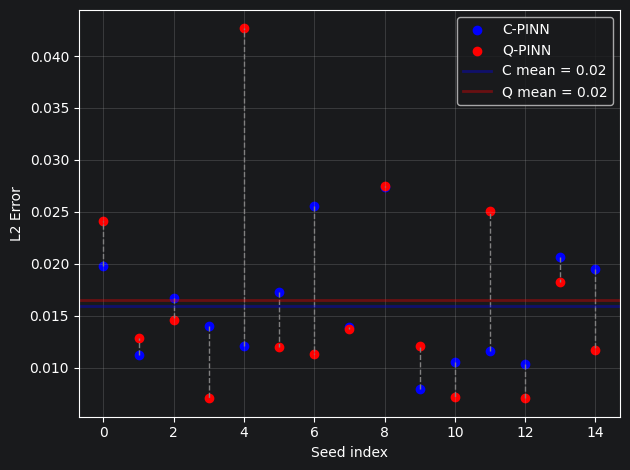

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# x-coordinates (indices)
x = np.arange(len(classical_l2))

# Plot points
plt.scatter(x, classical_l2, color='blue', label='C-PINN')
plt.scatter(x, quantum_l2, color='red', label='Q-PINN')

#means
mean1 = np.mean(classical_l2)
std1 = np.std(quantum_l2)

# Connect corresponding points
for i in range(len(classical_l2)):
    plt.plot(
        [x[i], x[i]],
        [classical_l2[i], quantum_l2[i]],
        linestyle='--',
        color='gray',
        linewidth=1
    )

# Mean lines
plt.axhline(mean1, color='blue', linewidth=2,
           label=f'C mean = {mean1:.2f}', alpha=0.35)
plt.axhline(mean2, color='red', linewidth=2,
           label=f'Q mean = {mean2:.2f}', alpha=0.35)


plt.xlabel('Seed index')
plt.ylabel('L2 Error')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Now try with more sample points to reduce randomness

In [ ]:
from src.sampler import DataSampler

new_classical_l2 = []
new_quantum_l2 = []


pde = HeatEquation(freq=0.5)

for i,seed in enumerate(SEEDS):

    pinn = ClassicalHeatQPINN().to(device)
    qpinn = MerlinHeatQPINN().to(device)


    # CLASSICAL MODEL
    sampler = DataSampler(pde=pde, n_interior=500, device=device, dtype=dtype)
    hist = train(model=pinn, pde=pde, sampler= sampler, loss_fn=total_loss, log_every=600, epochs=600, seed=seed, device=device, dtype=dtype)
    metrics, U_pred, U_true, _, _ = evaluate(model=pinn, pde=pde, device=device, dtype=dtype)

    new_classical_l2.append(metrics['rel_l2'])
    plot_solution_comparison(U_pred, U_true, save_path=f"../figures/reproducibility/bigsampler/classical_{i}.png", show=False)


    # QUANTUM MODEL
    sampler = DataSampler(pde=pde, n_interior=500, device=device, dtype=dtype)
    hist = train(model=qpinn, pde=pde, sampler=sampler, loss_fn=total_loss, log_every=600, epochs=600, seed=seed, device=device, dtype=dtype)
    metrics, U_pred, U_true, _, _ = evaluate(model=qpinn, pde=pde, device=device, dtype=dtype)

    new_quantum_l2.append(metrics['rel_l2'])
    plot_solution_comparison(U_pred, U_true, save_path=f"../figures/reproducibility/bigsampler/quantum_{i}.png", show=False)

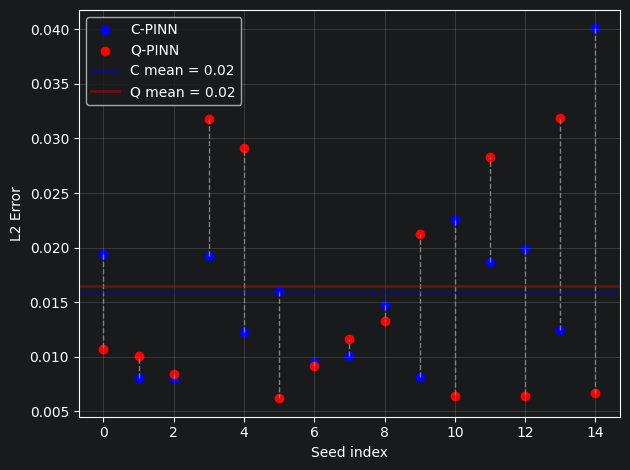

In [22]:
# x-coordinates (indices)
x = np.arange(len(new_classical_l2))

# Plot points
plt.scatter(x, new_classical_l2, color='blue', label='C-PINN')
plt.scatter(x, new_quantum_l2, color='red', label='Q-PINN')

#means
mean1 = np.mean(new_classical_l2)
mean2 = np.mean(new_quantum_l2)


# Connect corresponding points
for i in range(len(new_classical_l2)):
    plt.plot(
        [x[i], x[i]],
        [new_classical_l2[i], new_quantum_l2[i]],
        linestyle='--',
        color='gray',
        linewidth=1
    )


# Mean lines
plt.axhline(mean1, color='blue', linewidth=2,
           label=f'C mean = {mean1:.2f}', alpha=0.35)
plt.axhline(mean2, color='red', linewidth=2,
           label=f'Q mean = {mean2:.2f}', alpha=0.35)


plt.xlabel('Seed index')
plt.ylabel('L2 Error')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Thoughts
1) Il y a le sampler mais aussi l'initialisation des points du modele qui est random donc ca pourrait aussi dependre de ca
2) a tester aussi dans des cas ou le modele est moins bon, peut etre que les ~1% derreur quon a ici cest tellement peu que le bruit est plus ou moins inévitable, a tester donc avec plus hautes frequences (et en limitant le temps a t=0.5 ou 0.2 pour eviter de parasiter les resultats avec du $U_{true} \approx const.$)

## Repeat process with $f=2.5$ and $t \in [0,0.3]$
Here we usually have total failure of the classical model while the quantum one manages

Parameters — total: 250  trainable: 250

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 4.7388e+00 | PDE: 1.83e-03 | Cons: 3.08e-01 | IC: 4.70e-01 | BC: 9.62e-03 | Time: 0.0s
Epoch   600/600 | Loss: 3.2151e+00 | PDE: 3.15e-02 | Cons: 1.90e+00 | IC: 2.92e-01 | BC: 7.74e-02 | Time: 2.4s

Done — 2.4s total
Evaluating on 60×60 grid …
  Relative L2 : 8.0187e-01
  MAE         : 2.0277e-01
  Max abs err : 1.1619e+00
  RMSE        : 2.9094e-01
Saved: ../figures/reproducibility/hf/classical_0.png
Parameters — total: 270  trainable: 270

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 5.5983e+00 | PDE: 1.16e-04 | Cons: 4.54e-02 | IC: 5.37e-01 | BC: 2.25e-01 | Time: 0.1s
Epoch   600/600 | Loss: 4.7959e-01 | PDE: 8.87e-02 | Cons: 2.57e+00 | IC: 1.12e-02 | BC: 2.15e-02 | Time: 59.7s

Done — 59.7s total
Evaluating on 60×60 grid …
  Relative L2 : 1.7592e-01
  MAE         : 5.1587e-02
  Max abs err : 3.0498e-01
  RMSE        : 6.3827e-02
Sav

/home/jad/PycharmProjects/QPINN-Analysis/src/plotter.py:95: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(1, 3, figsize=(15,4))


Saved: ../figures/reproducibility/hf/classical_10.png
Parameters — total: 270  trainable: 270

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 6.2121e+00 | PDE: 1.92e-04 | Cons: 3.50e-02 | IC: 6.10e-01 | BC: 1.05e-01 | Time: 0.2s
Epoch   600/600 | Loss: 7.4307e-01 | PDE: 1.32e-01 | Cons: 3.96e+00 | IC: 1.76e-02 | BC: 3.88e-02 | Time: 84.9s

Done — 84.9s total
Evaluating on 60×60 grid …
  Relative L2 : 2.1396e-01
  MAE         : 6.2696e-02
  Max abs err : 2.3576e-01
  RMSE        : 7.7631e-02
Saved: ../figures/reproducibility/hf/quantum_10.png
Parameters — total: 250  trainable: 250

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 7.9474e+00 | PDE: 3.36e-04 | Cons: 1.77e-03 | IC: 7.82e-01 | BC: 1.30e-01 | Time: 0.0s
Epoch   600/600 | Loss: 2.6904e+00 | PDE: 5.51e-02 | Cons: 4.73e+00 | IC: 1.83e-01 | BC: 3.29e-01 | Time: 3.3s

Done — 3.3s total
Evaluating on 60×60 grid …
  Relative L2 : 5.6770e-01
  MAE         : 1.6386e-01
  Ma

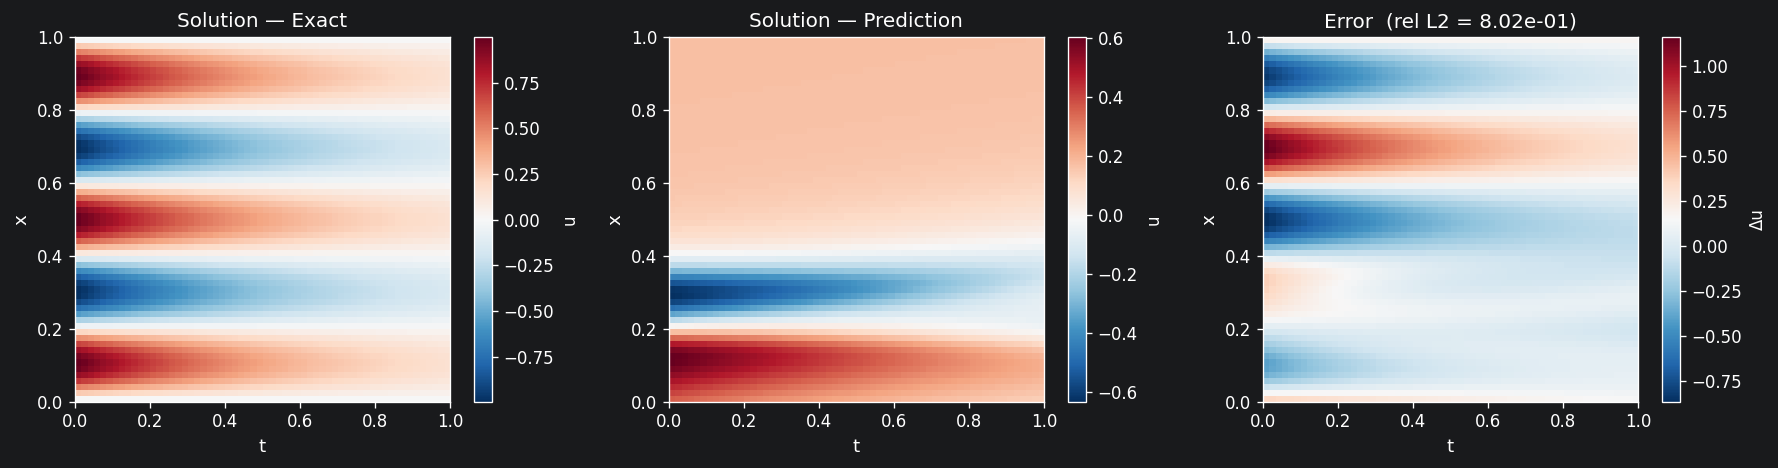

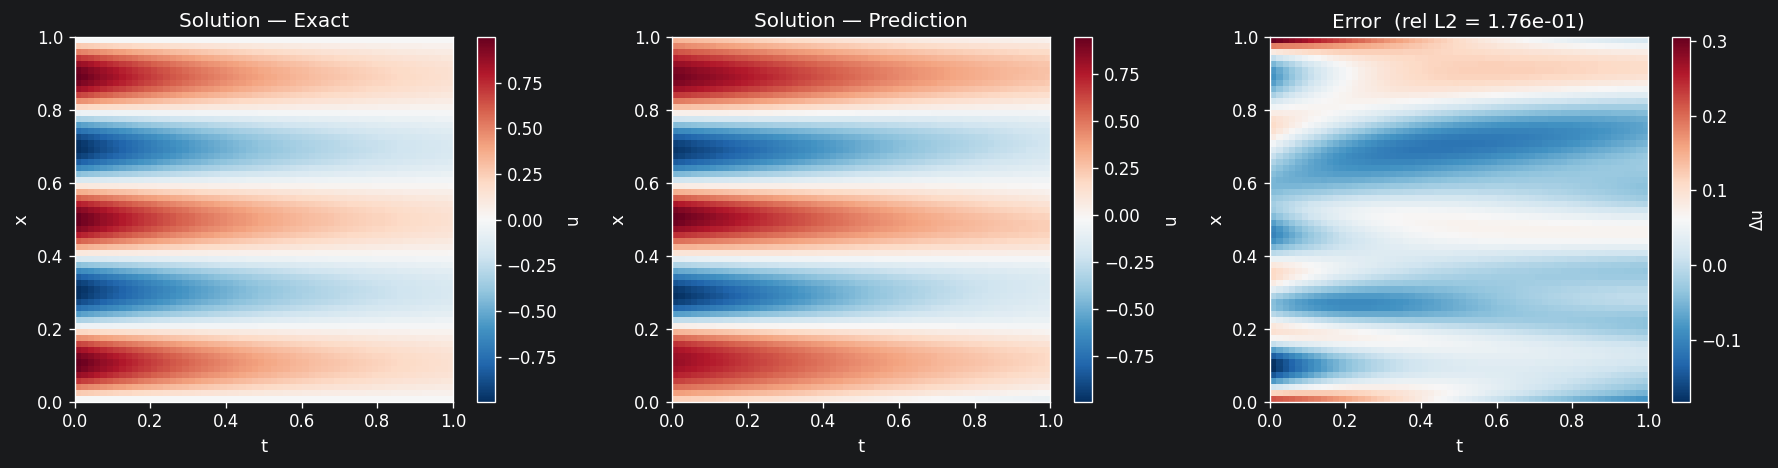

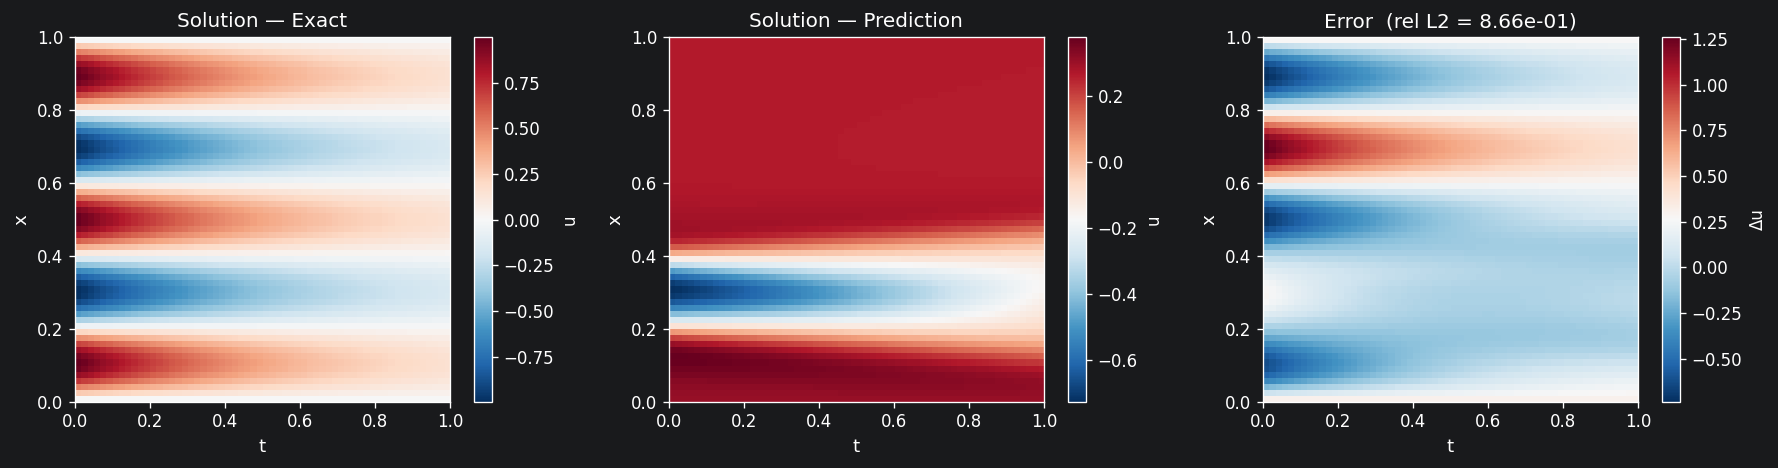

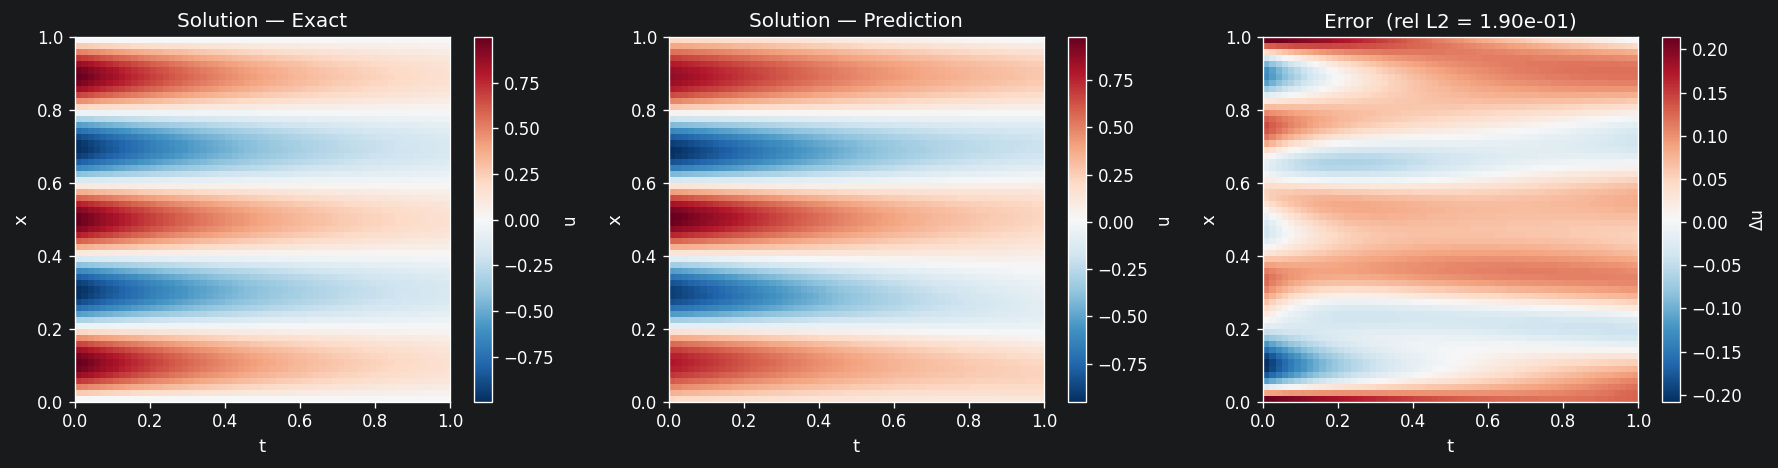

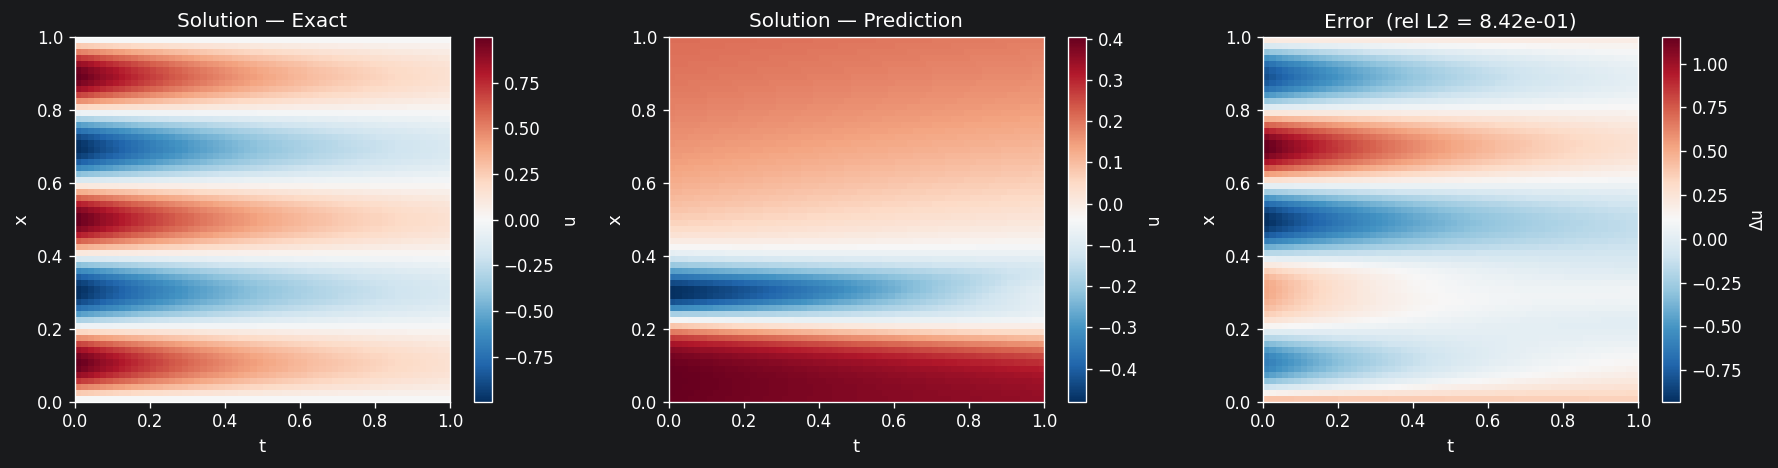

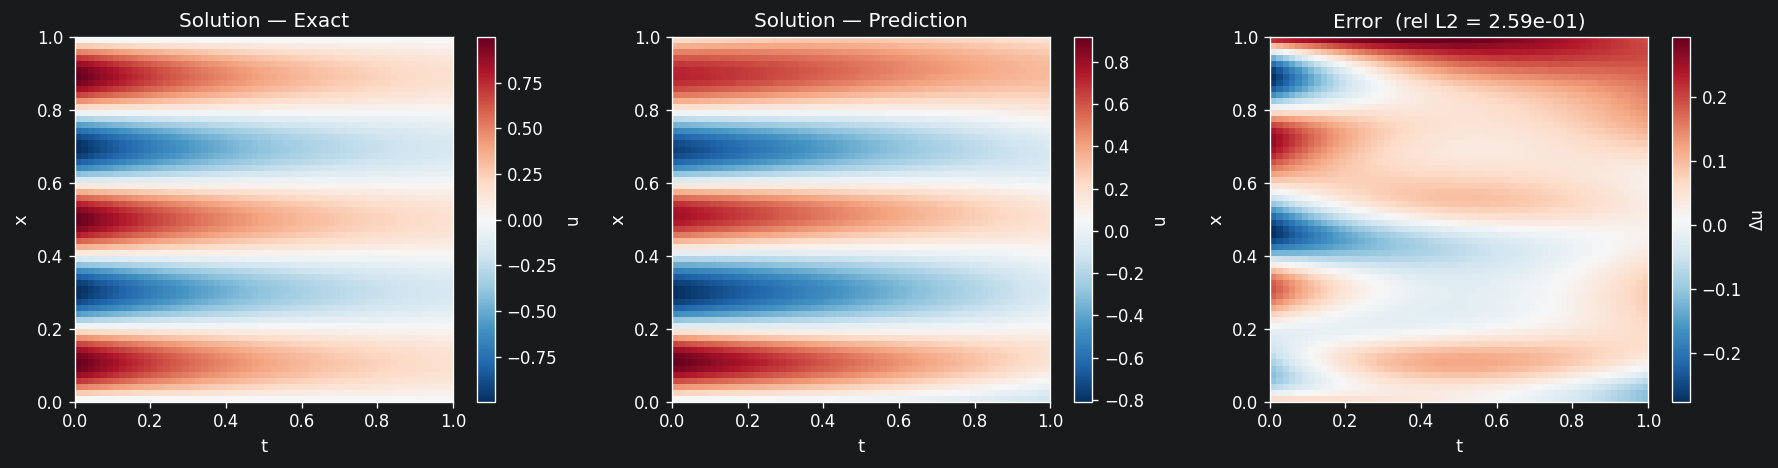

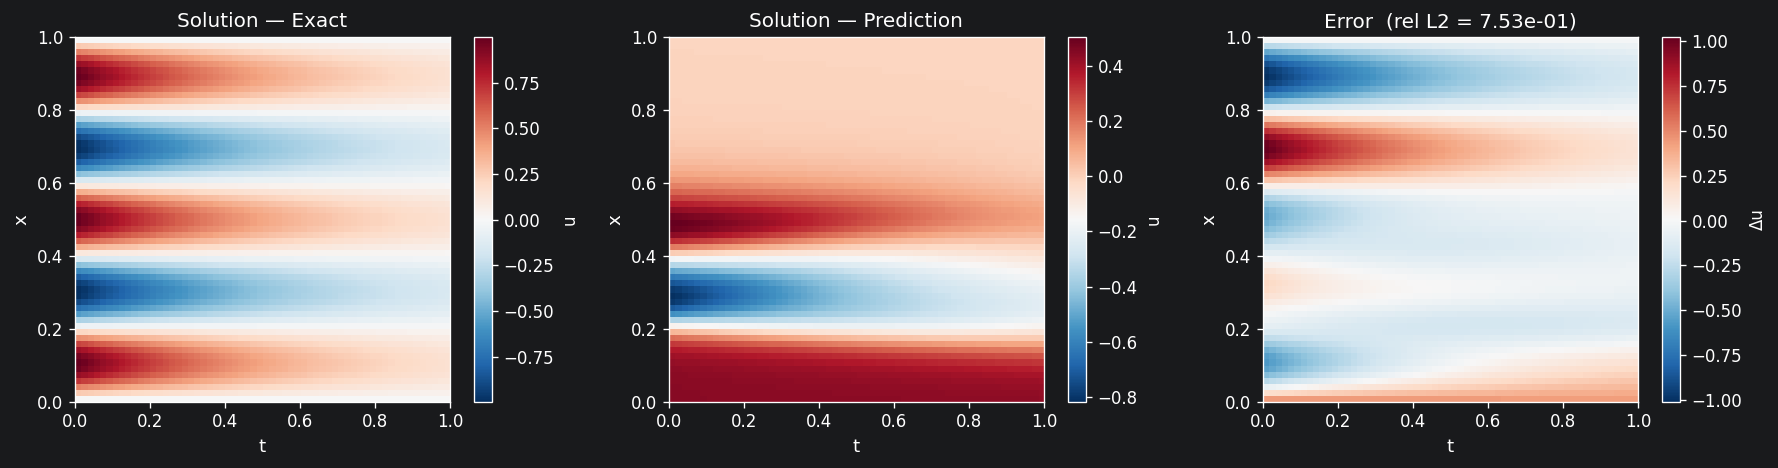

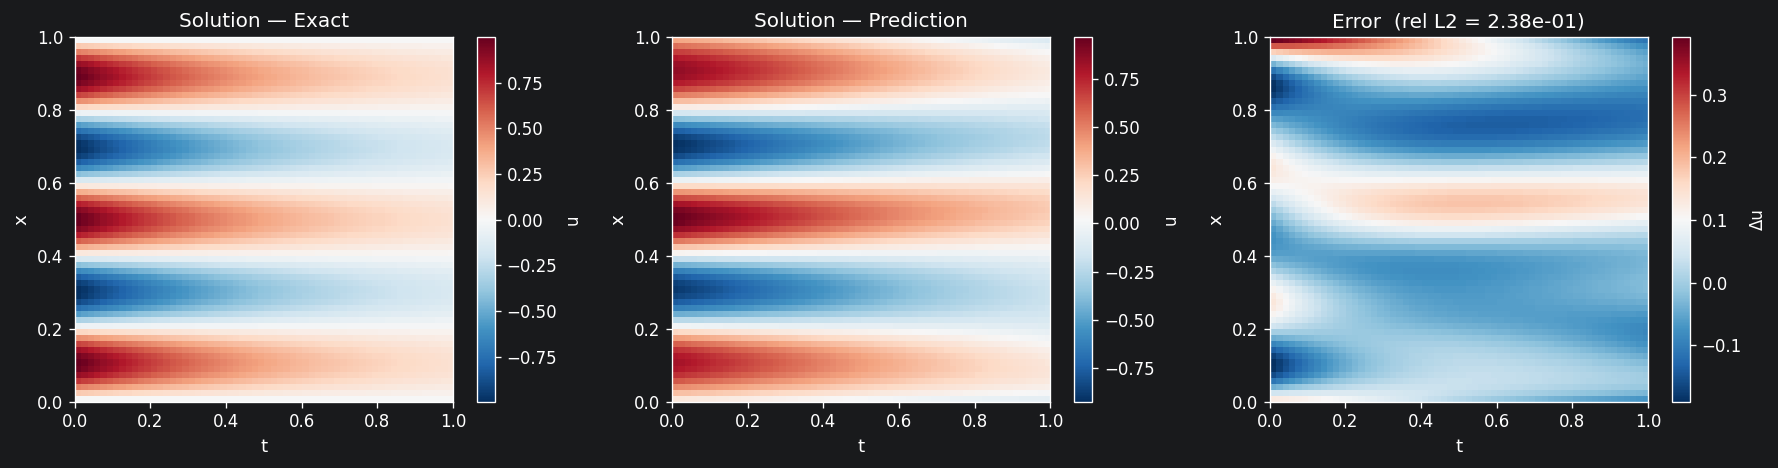

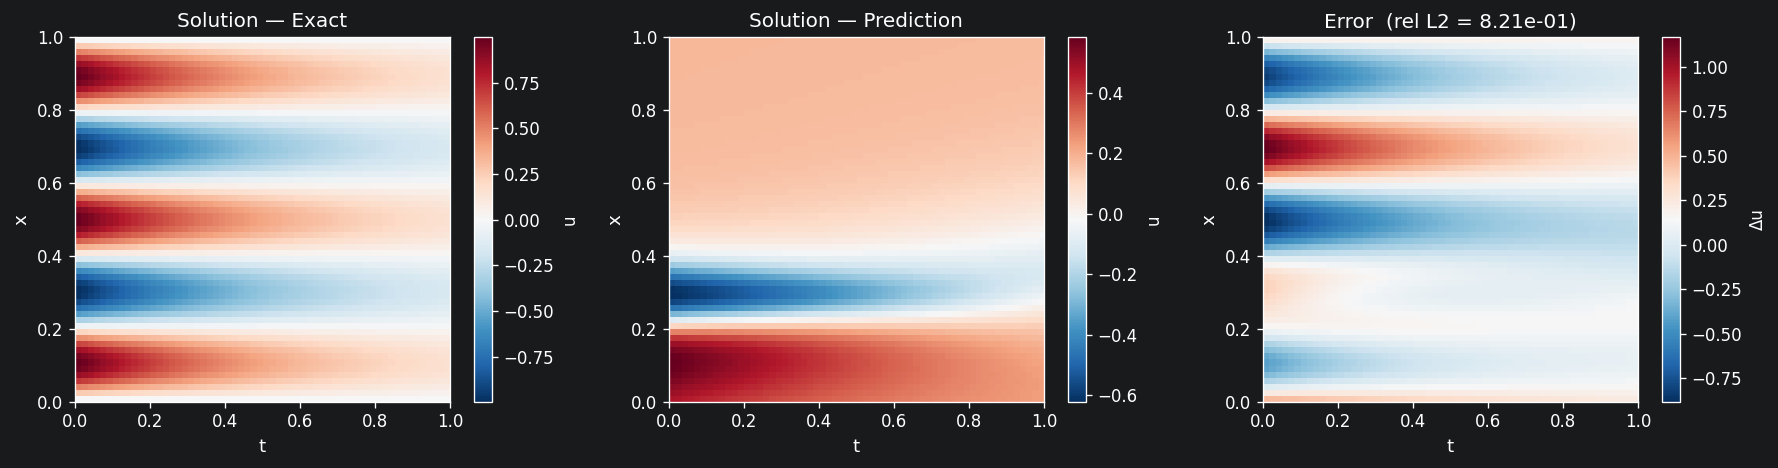

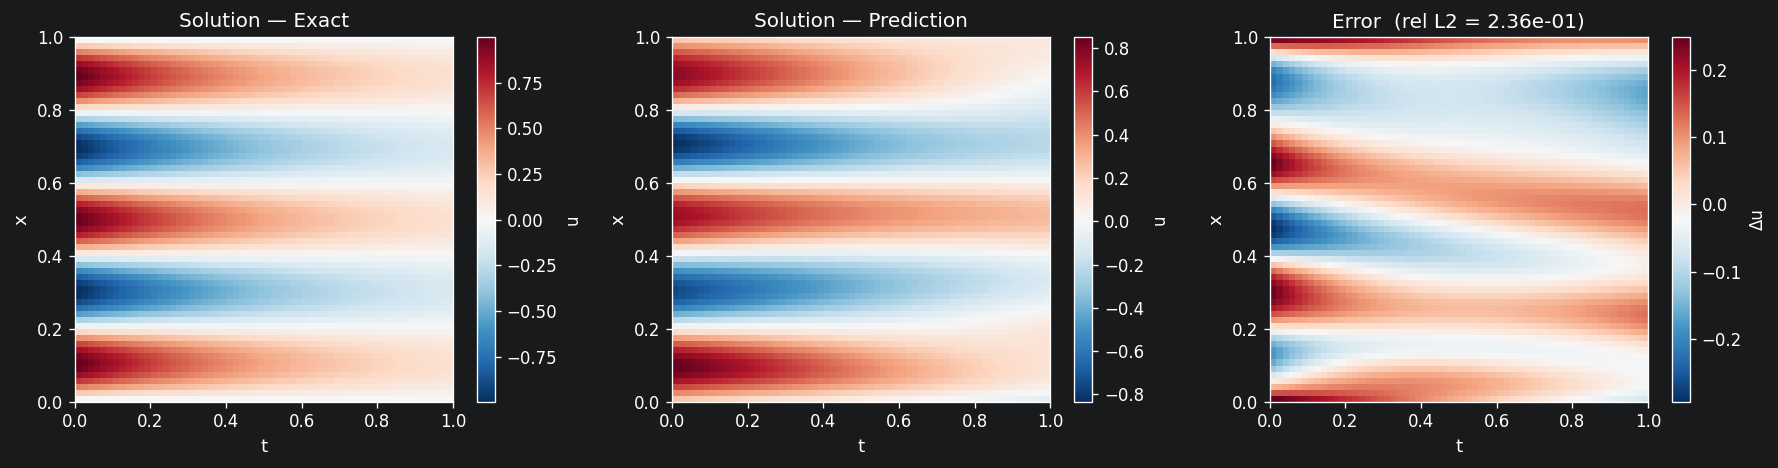

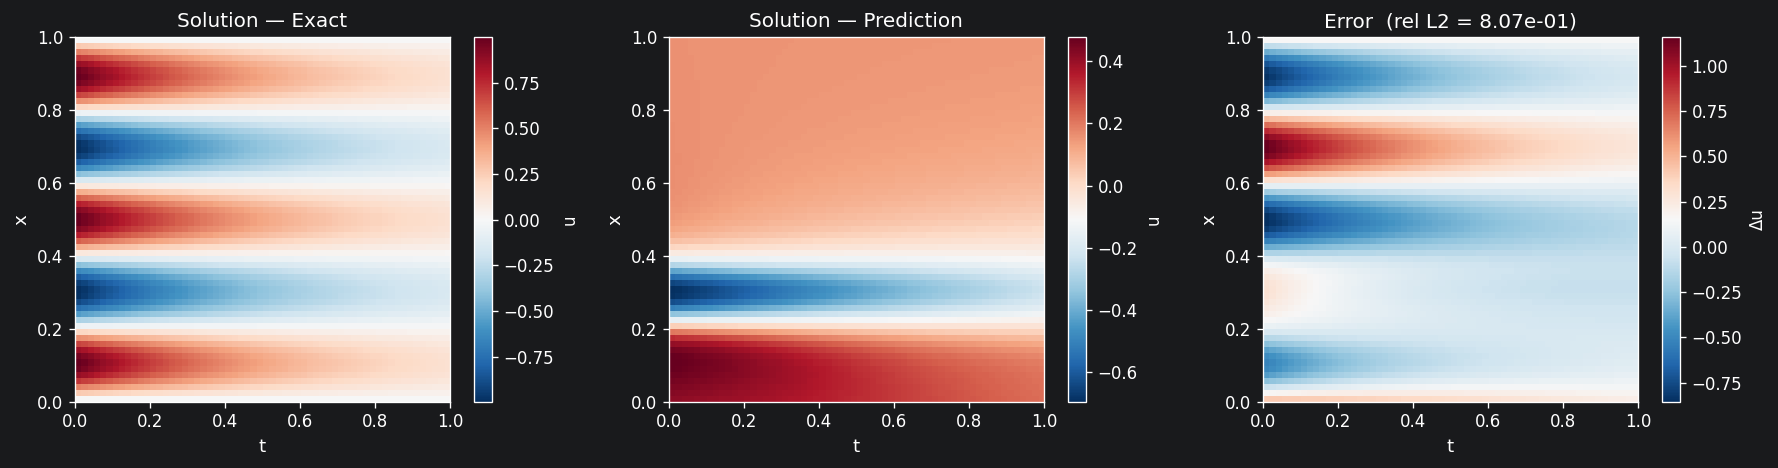

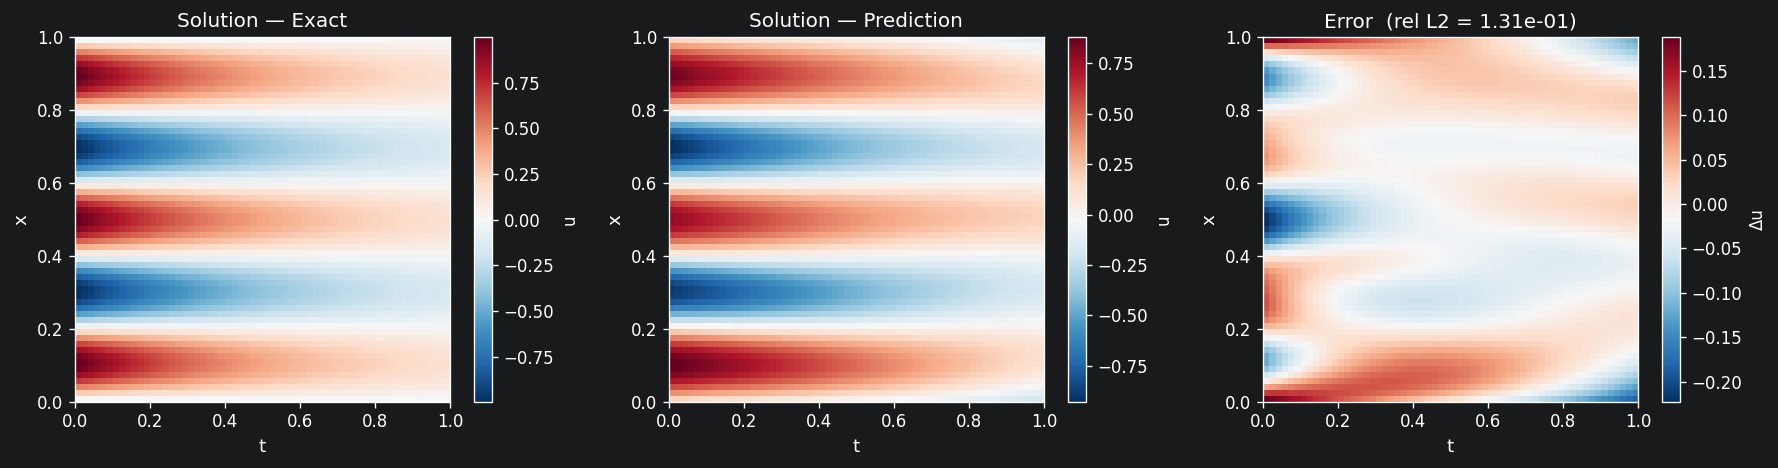

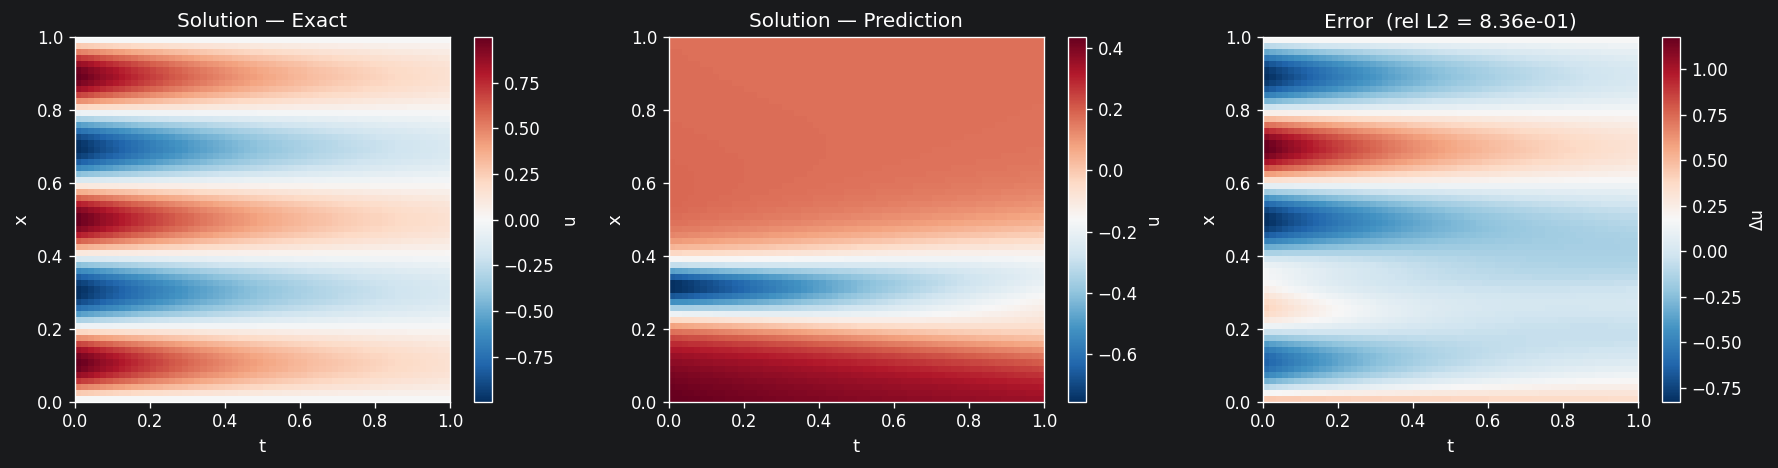

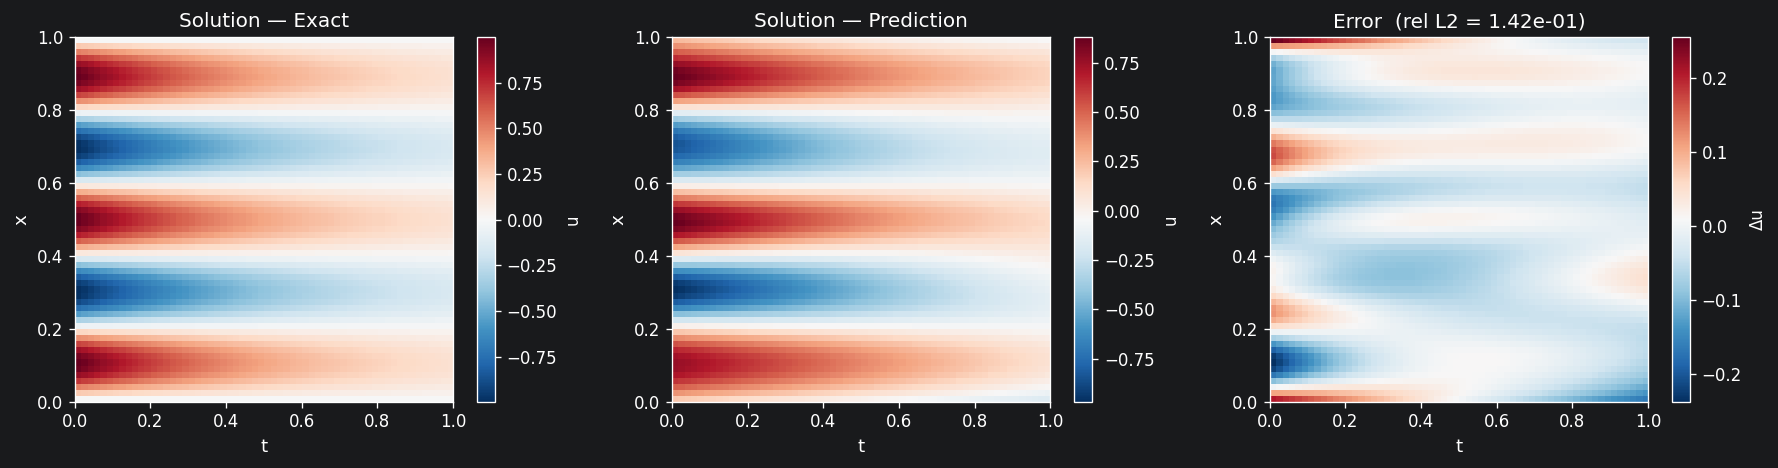

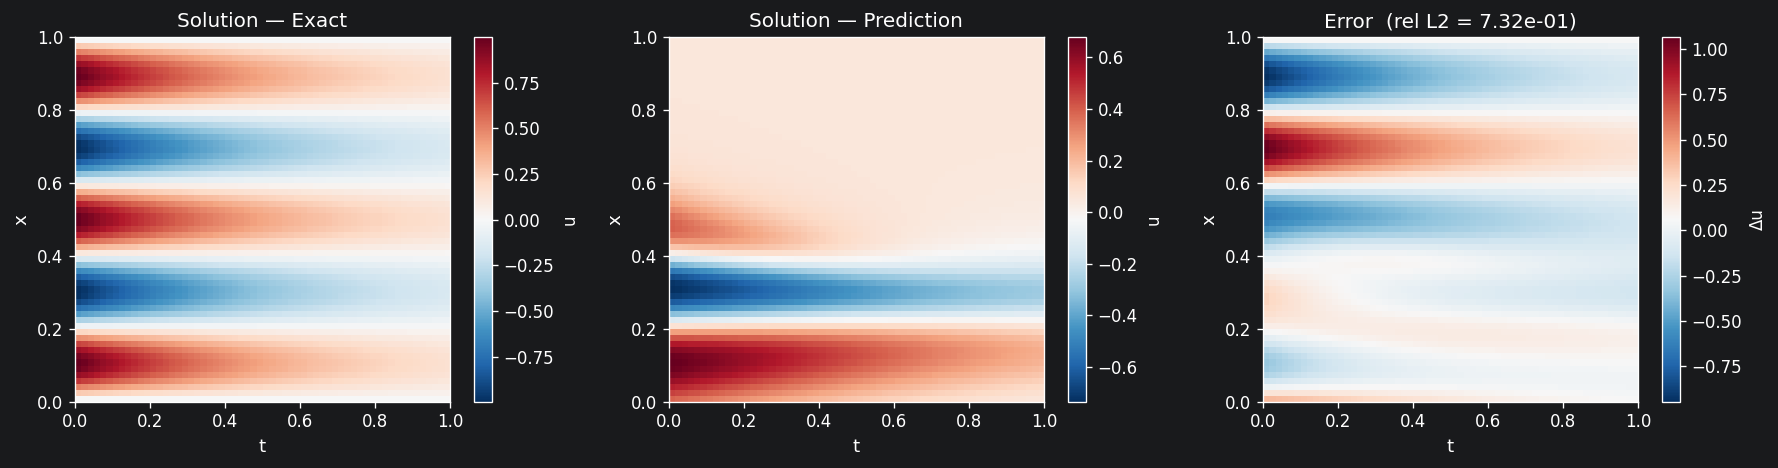

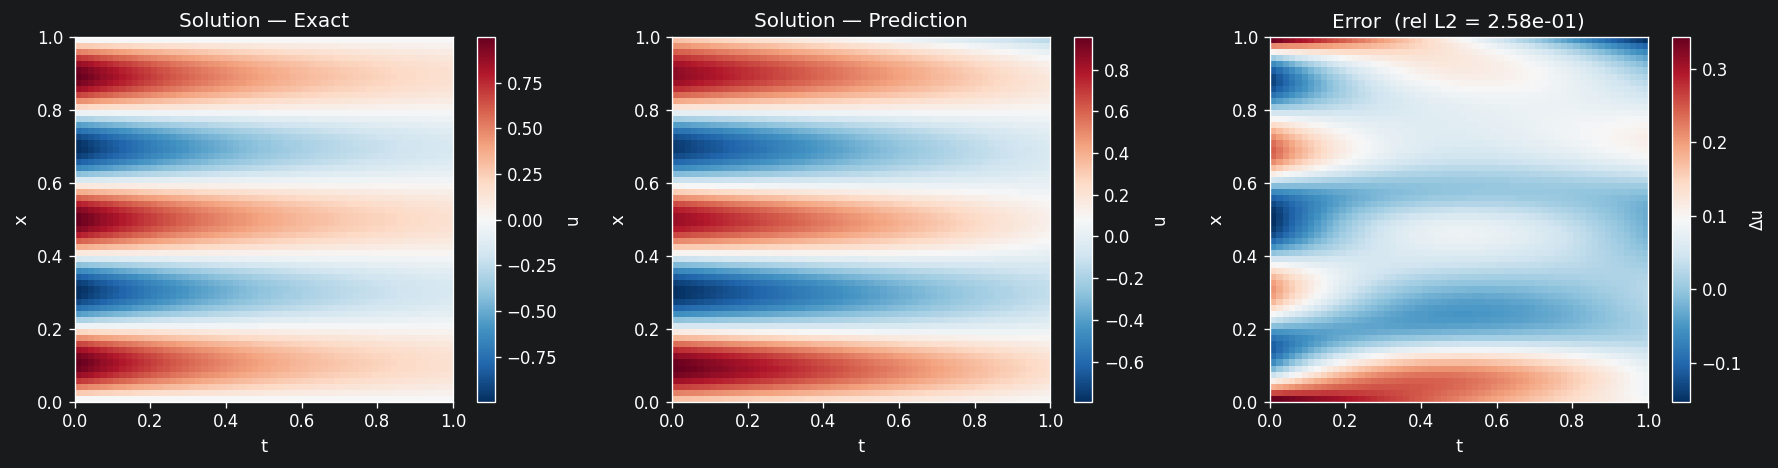

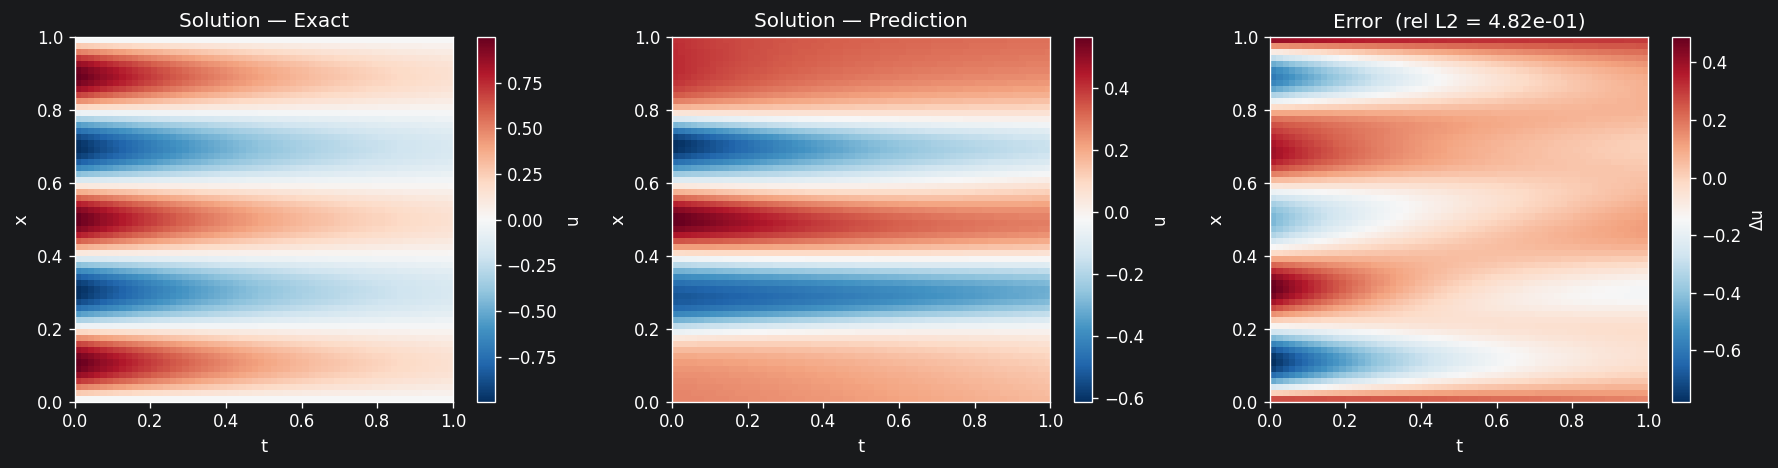

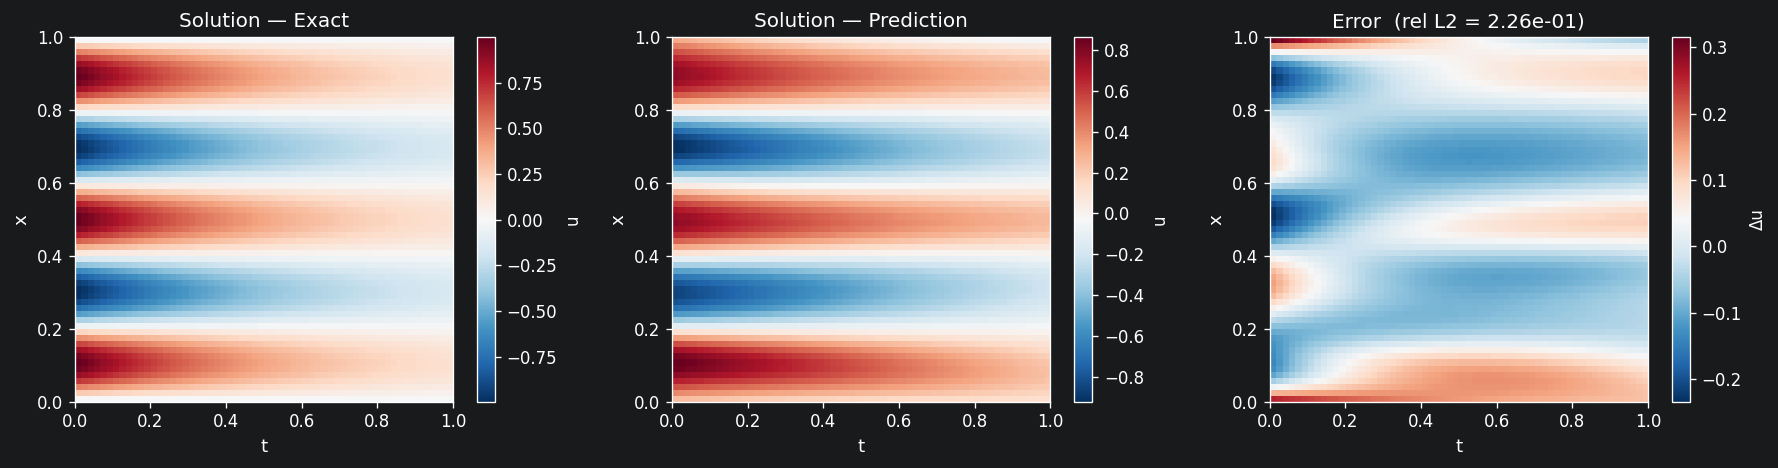

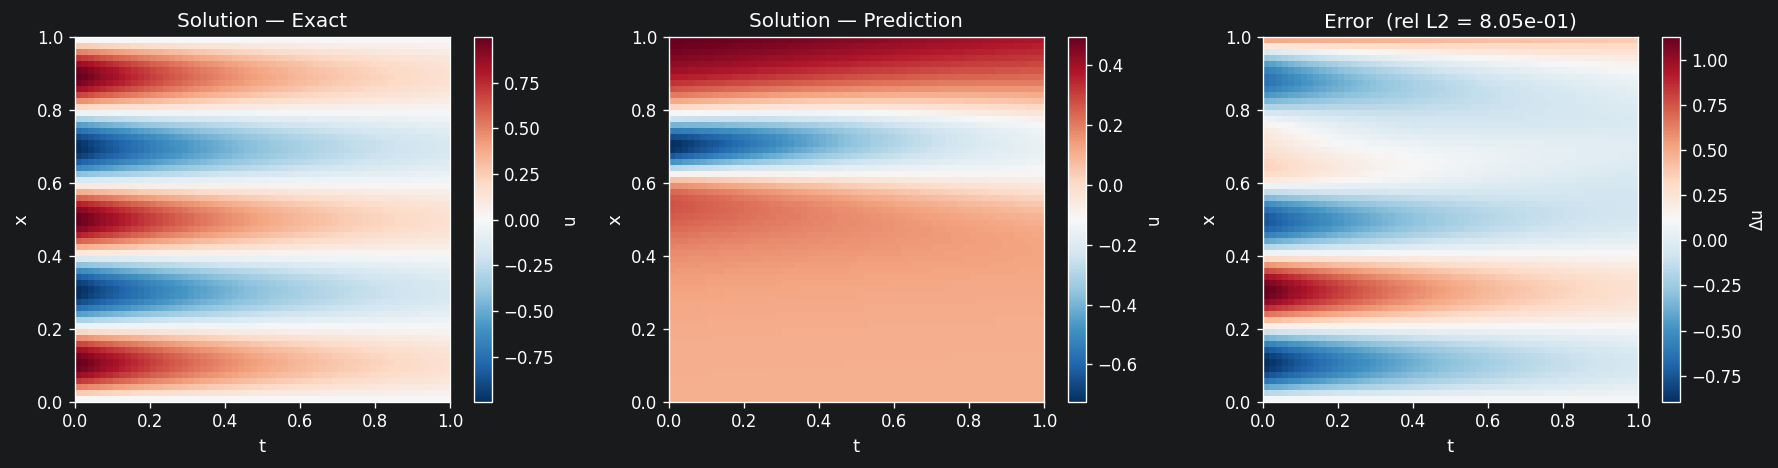

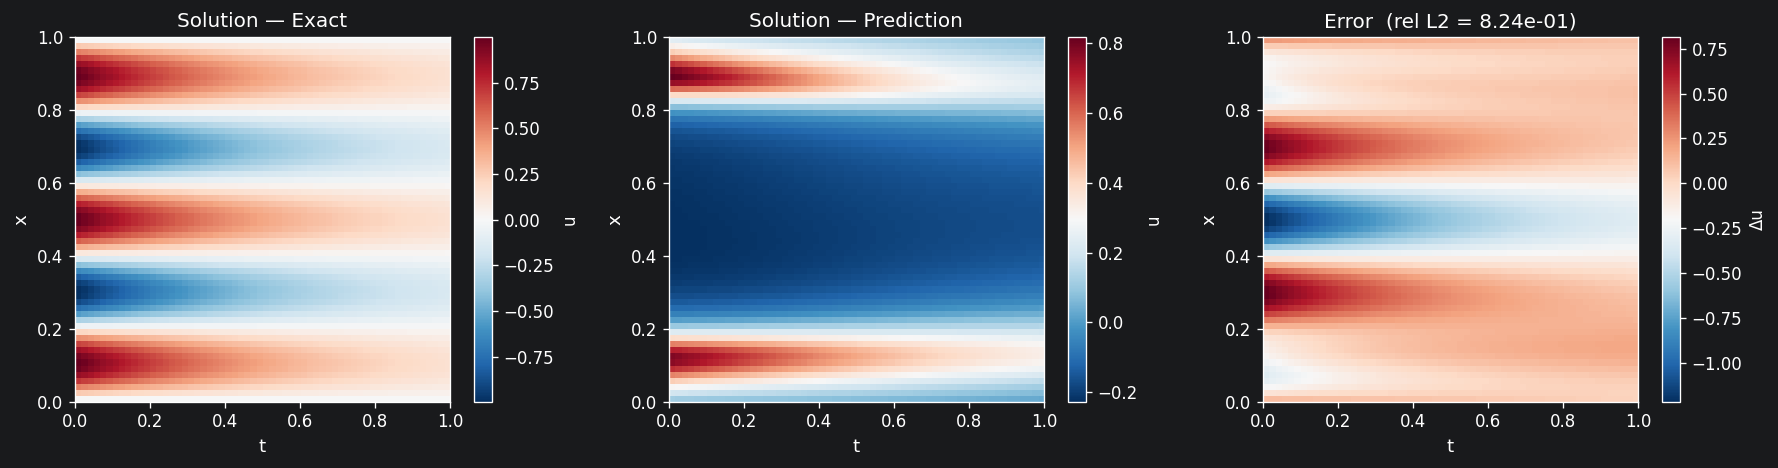

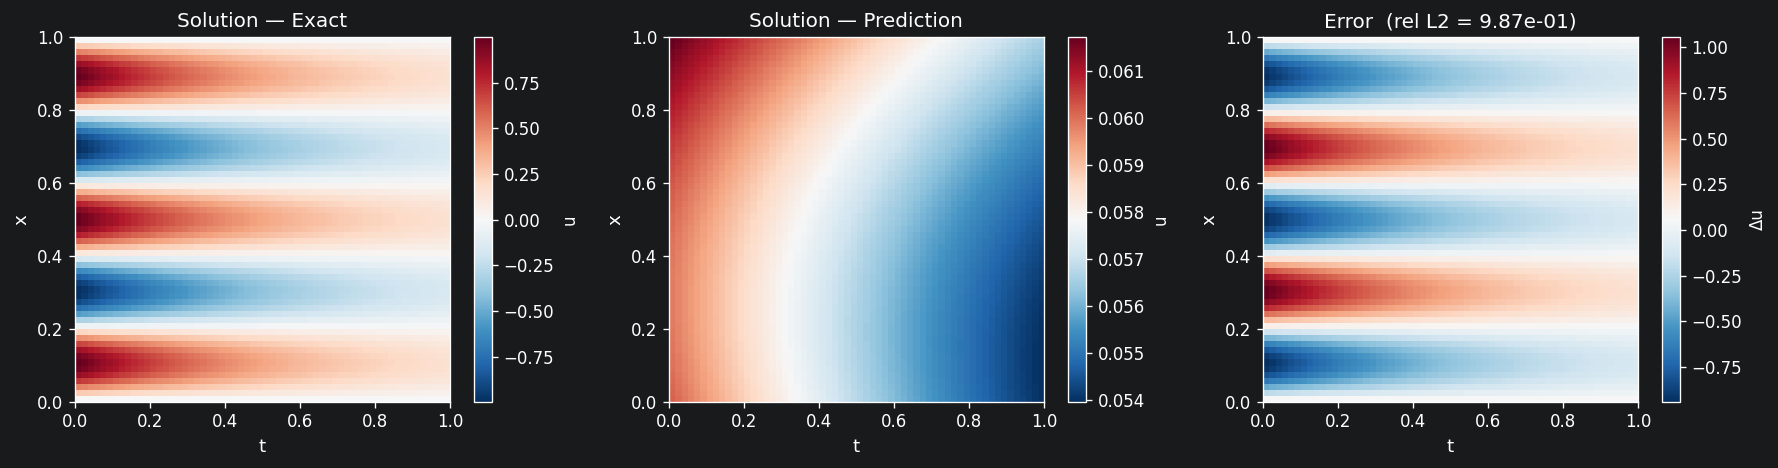

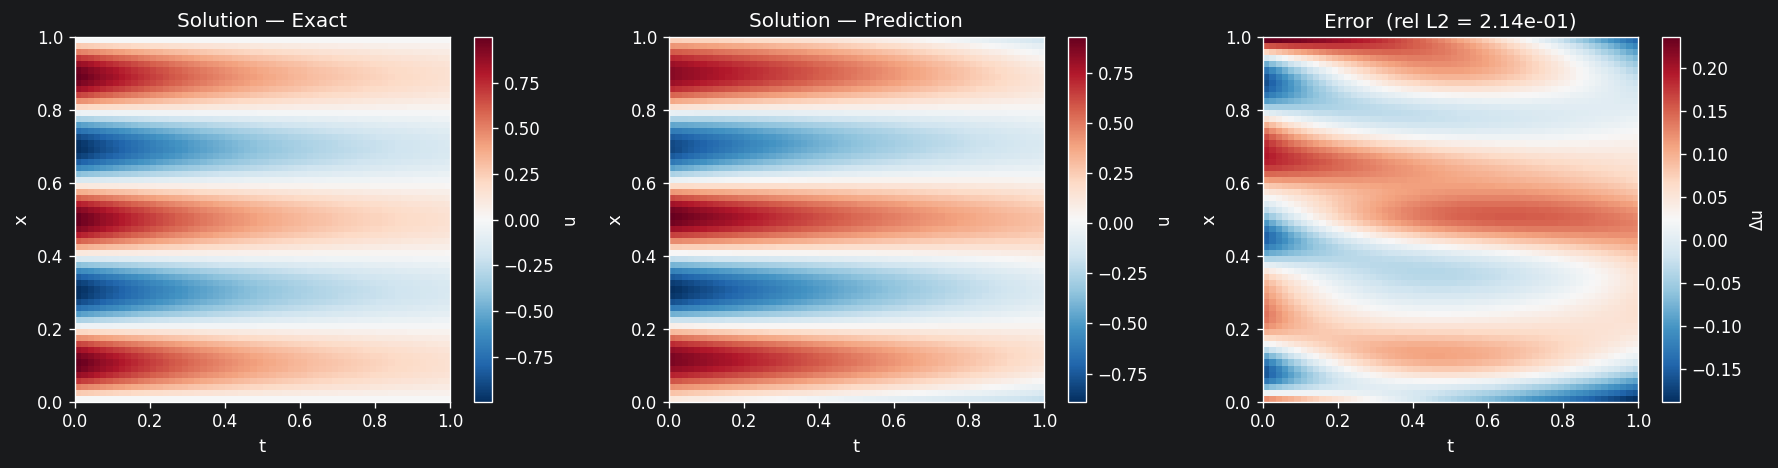

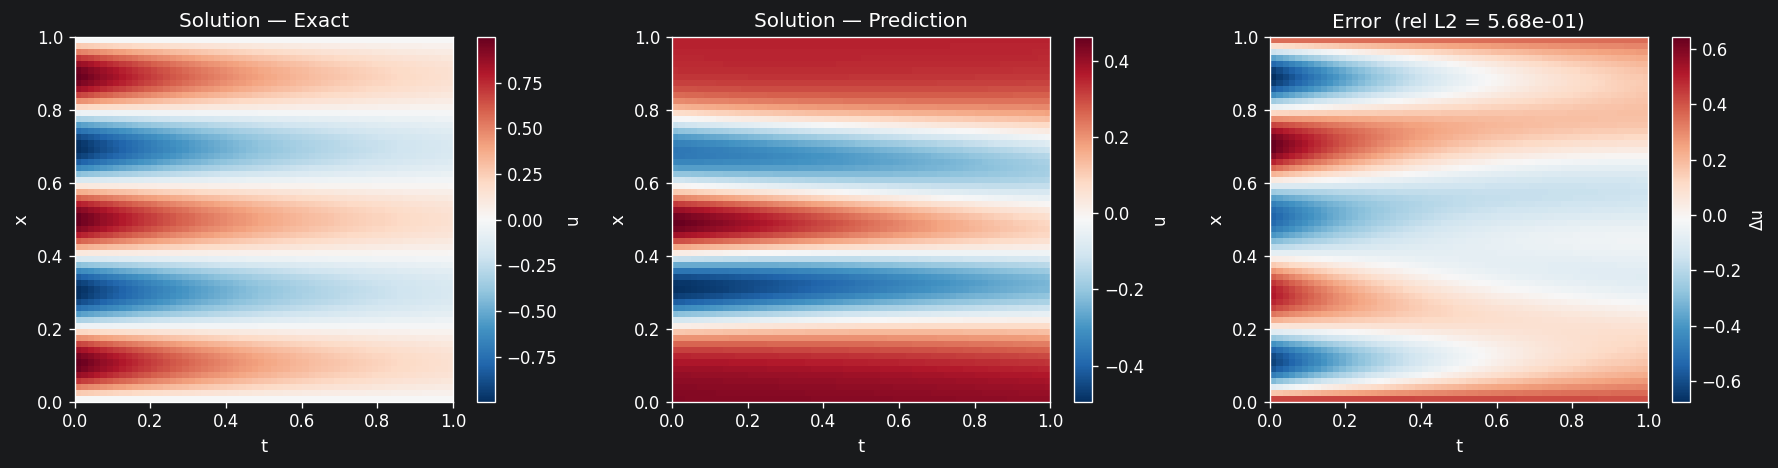

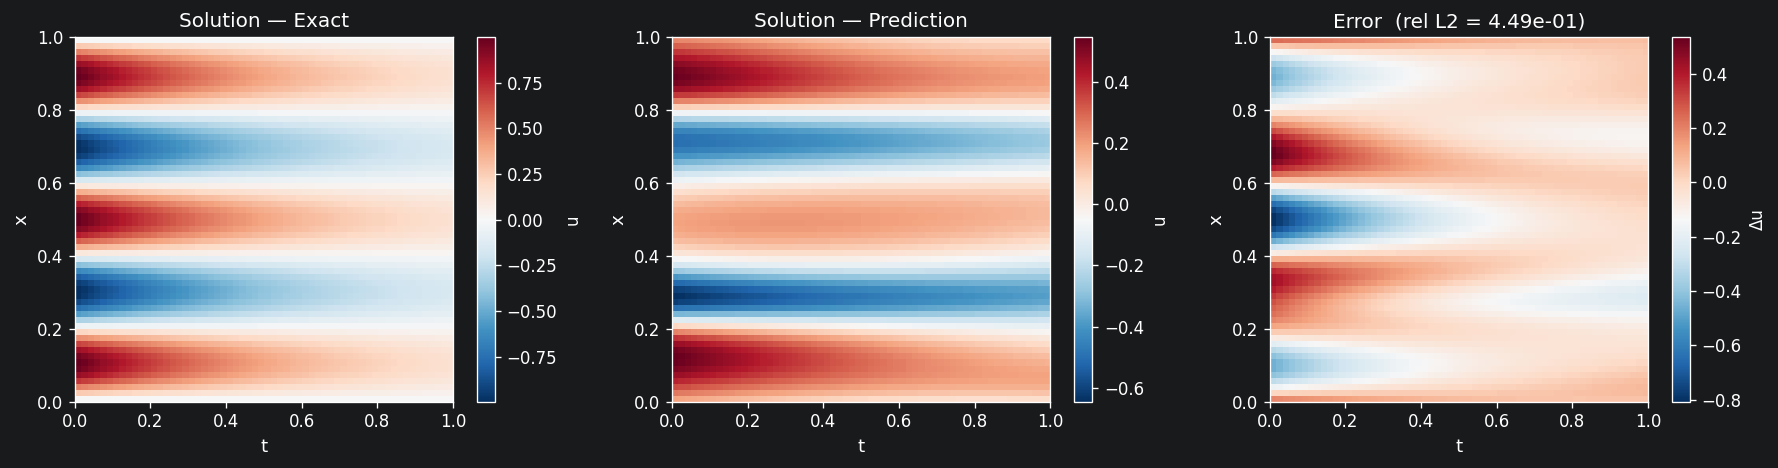

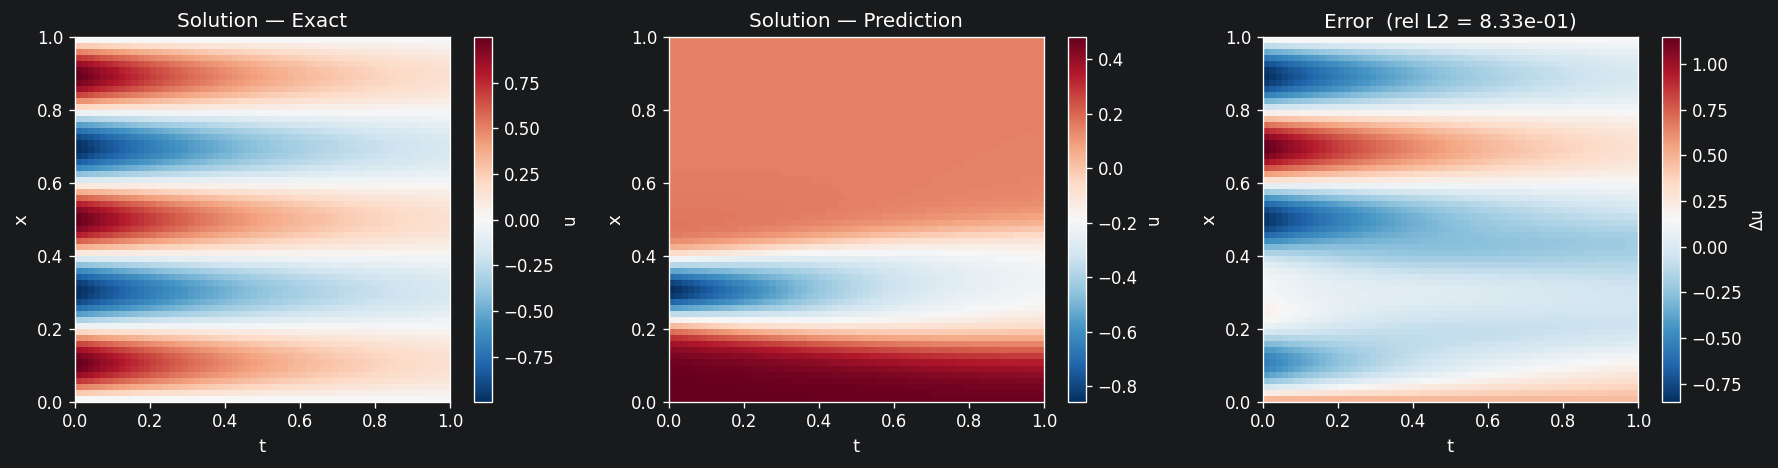

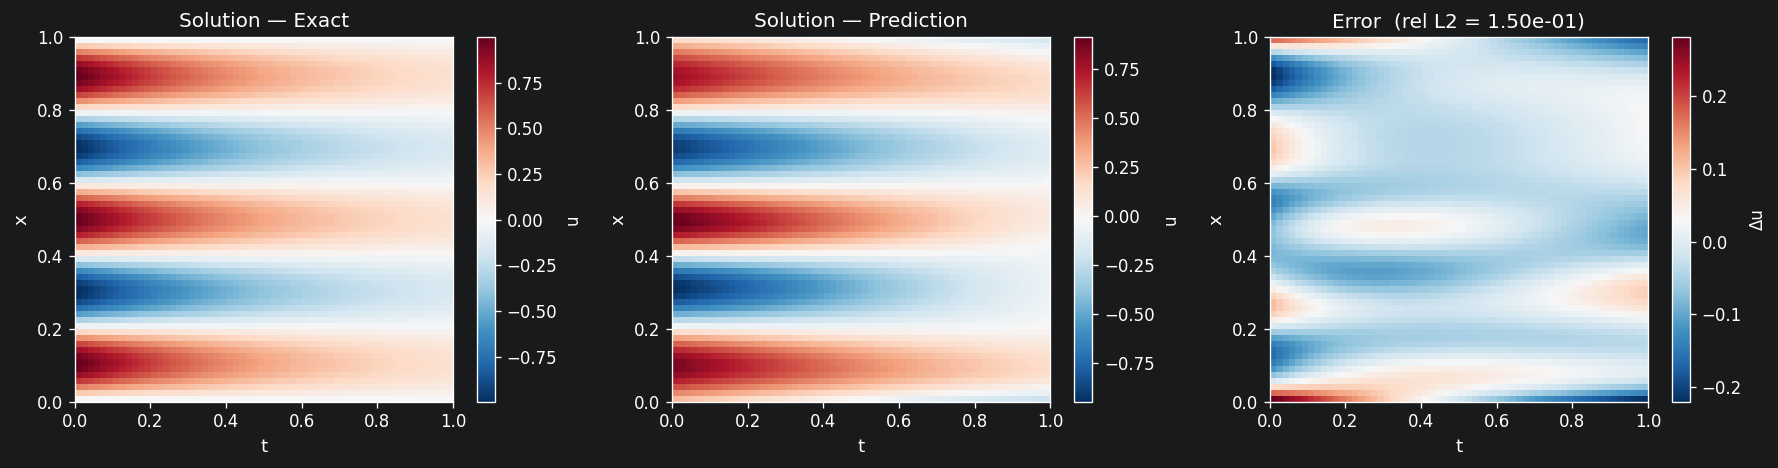

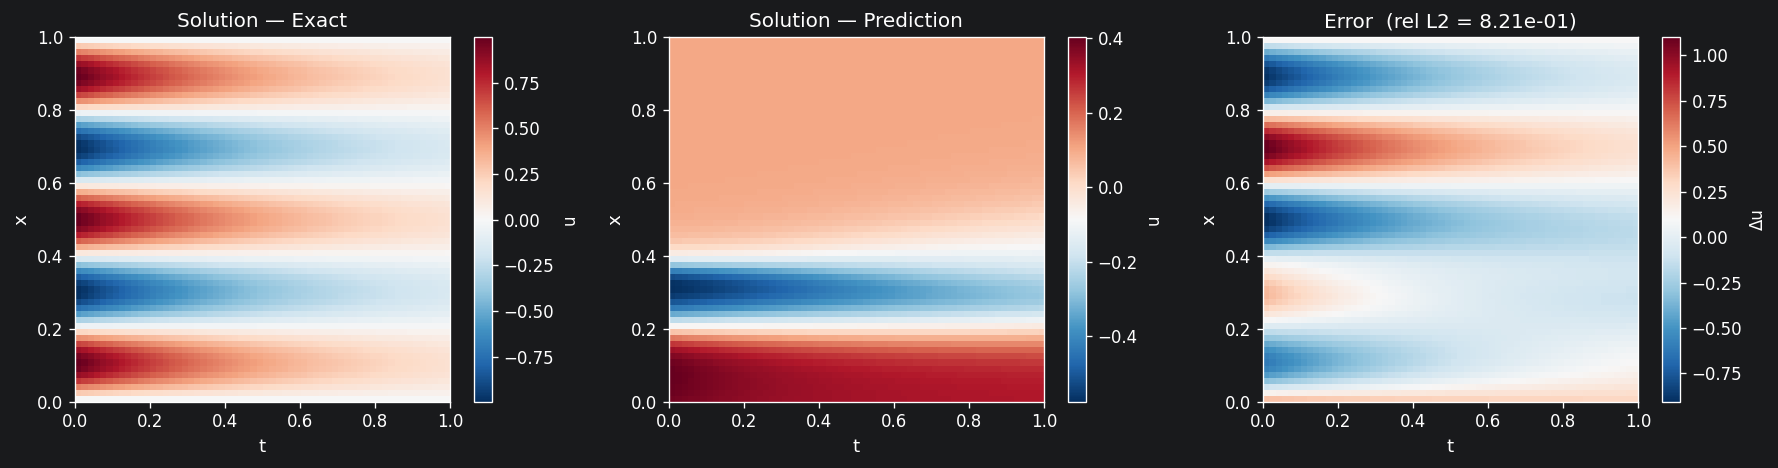

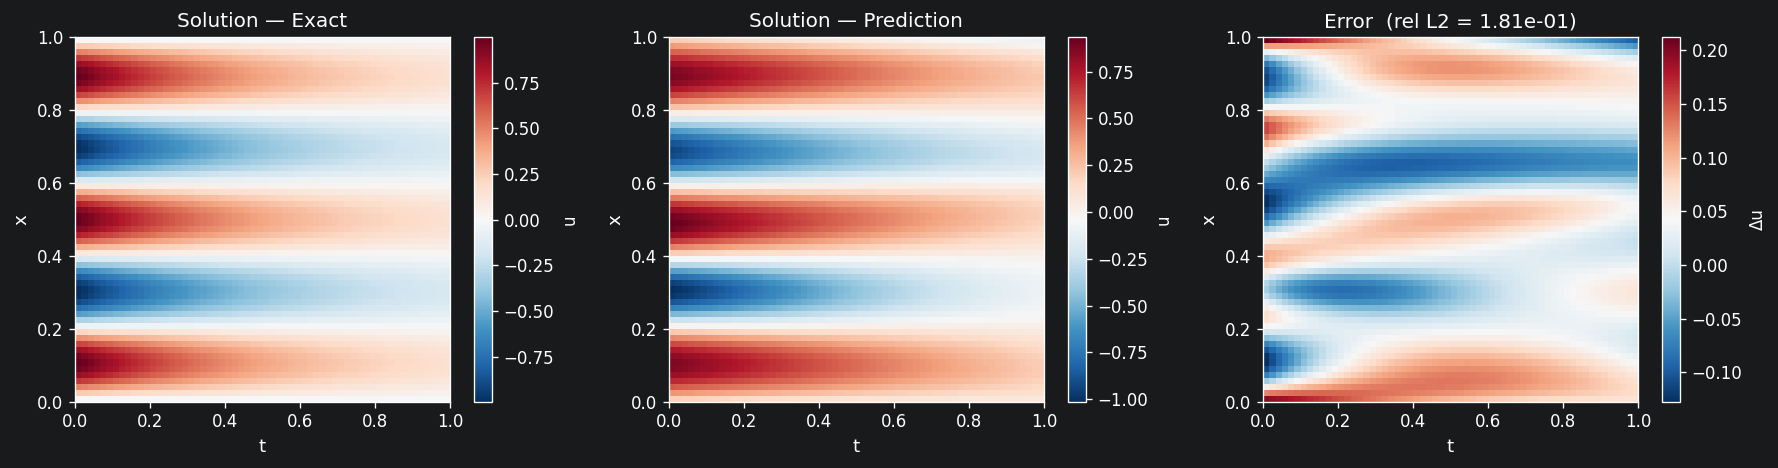

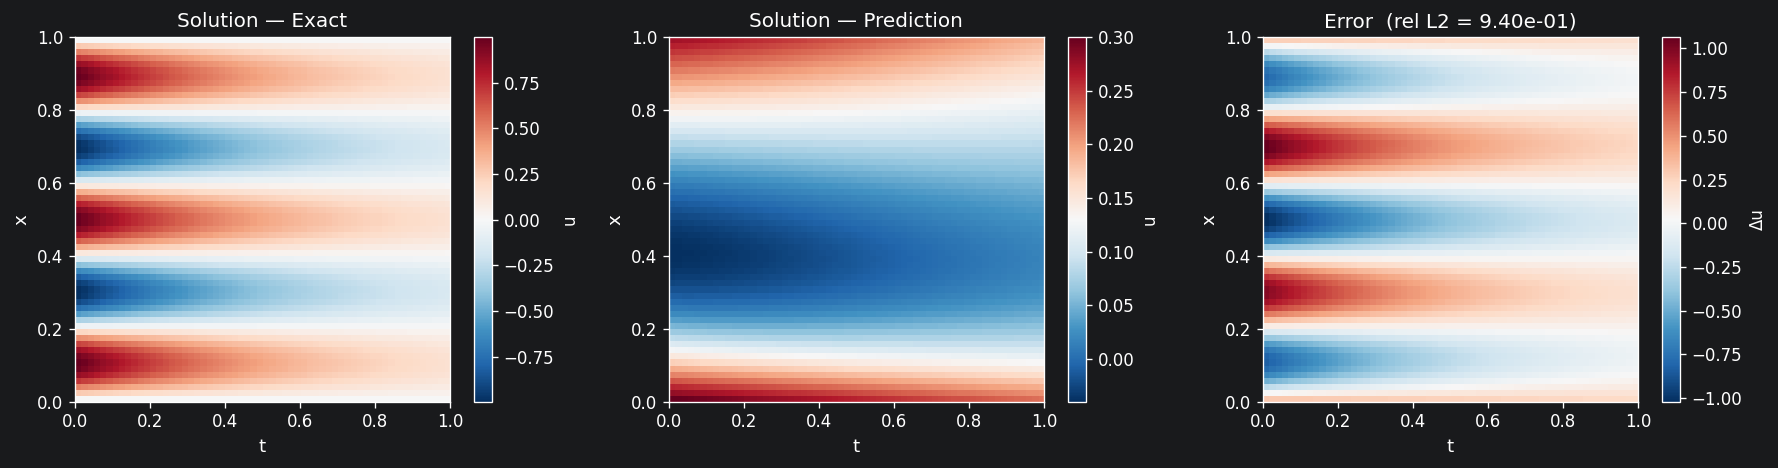

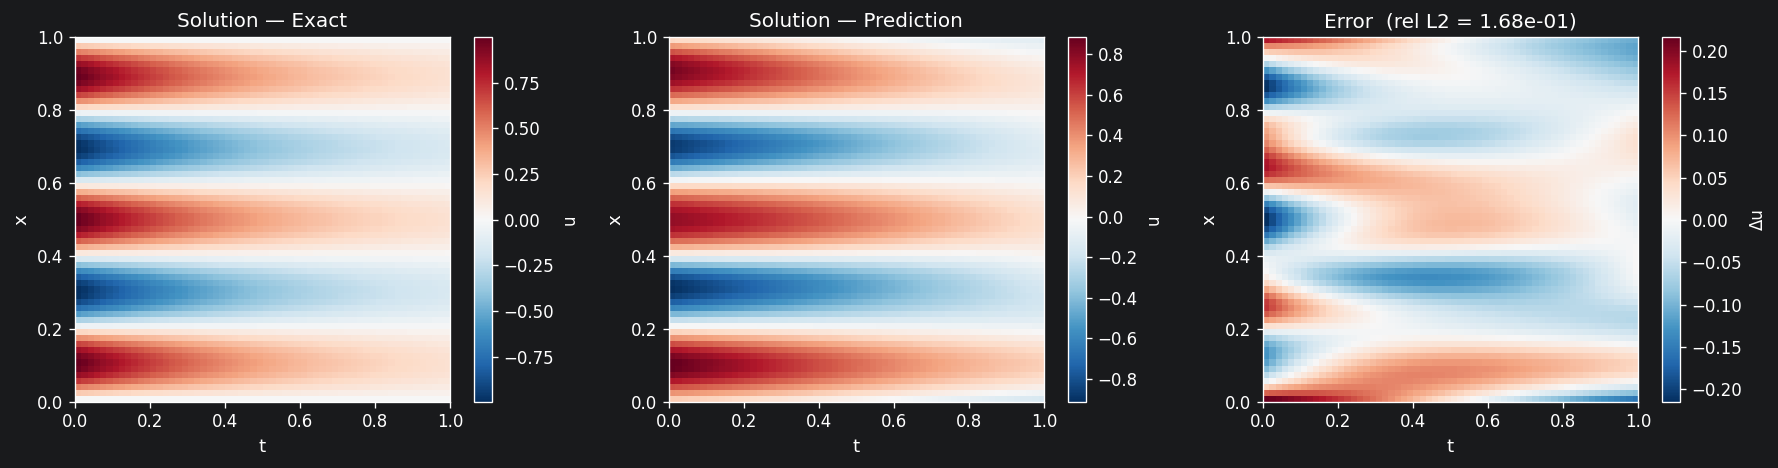

In [3]:
pde = HeatEquation(freq=2.5, t_max=0.3)

hf_classical_l2 =[]
hf_quantum_l2 =[]


for i,seed in enumerate(SEEDS):

    pinn = ClassicalHeatQPINN().to(device)
    qpinn = MerlinHeatQPINN().to(device)

    # CLASSICAL MODEL
    hist = train(model=pinn, pde=pde, loss_fn=total_loss, log_every=600, epochs=600, seed=seed, device=device, dtype=dtype)
    metrics, U_pred, U_true, _, _ = evaluate(model=pinn, pde=pde, device=device, dtype=dtype)

    hf_classical_l2.append(metrics['rel_l2'])
    plot_solution_comparison(U_pred, U_true, save_path=f"../figures/reproducibility/hf/classical_{i}.png", show=False)


    # QUANTUM MODEL
    hist = train(model=qpinn, pde=pde, loss_fn=total_loss, log_every=600, epochs=600, seed=seed, device=device, dtype=dtype)
    metrics, U_pred, U_true, _, _ = evaluate(model=qpinn, pde=pde, device=device, dtype=dtype)

    hf_quantum_l2.append(metrics['rel_l2'])
    plot_solution_comparison(U_pred, U_true, save_path=f"../figures/reproducibility/hf/quantum_{i}.png", show=False)

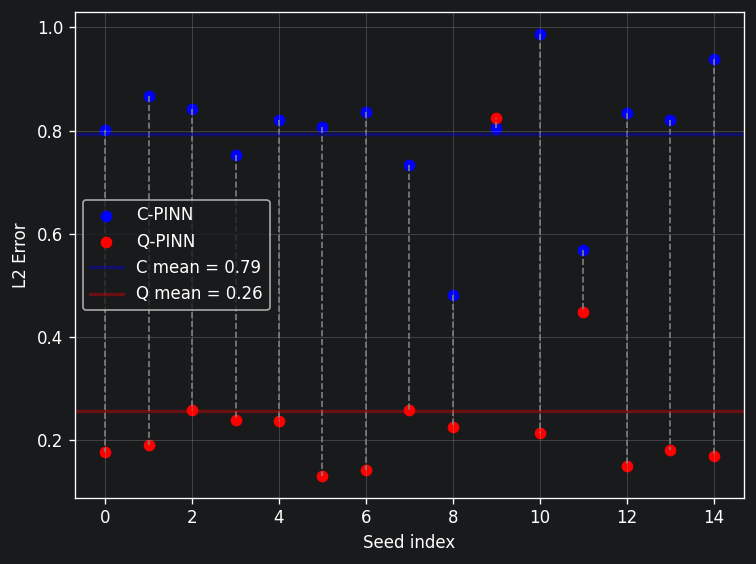

In [8]:
import numpy as np
# seed_l2_comparison(hf_classical_l2, hf_quantum_l2, "C-PINN", "Q-PINN")


# x-coordinates (indices)
x = np.arange(len(hf_classical_l2))

# Plot points
plt.scatter(x, hf_classical_l2, color='blue', label='C-PINN')
plt.scatter(x, hf_quantum_l2, color='red', label='Q-PINN')

#means
mean1 = np.mean(hf_classical_l2)
mean2 = np.mean(hf_quantum_l2)


# Connect corresponding points
for i in range(len(hf_classical_l2)):
    plt.plot(
        [x[i], x[i]],
        [hf_classical_l2[i], hf_quantum_l2[i]],
        linestyle='--',
        color='gray',
        linewidth=1
    )


# Mean lines
plt.axhline(mean1, color='blue', linewidth=2,
           label=f'C mean = {mean1:.2f}', alpha=0.35)
plt.axhline(mean2, color='red', linewidth=2,
           label=f'Q mean = {mean2:.2f}', alpha=0.35)


plt.xlabel('Seed index')
plt.ylabel('L2 Error')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()